In [6]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# 1. Carga de datos ambientales (Carga del archivo solicitado por el usuario)
df = pd.read_excel('datos_ambiental_evaluacion_tema9.xlsx', index_col='estacion')
# Se seleccionan las columnas numéricas correctas para este dataset
num_cols = ['pm10_ugm3', 'no2_ppb', 'ruido_db']

# 2. Imputación de valores faltantes con la mediana
df_clean = df[num_cols].fillna(df[num_cols].median())

# 3. Estandarización Z-Score (Media=0, DesvEst=1)
scaler_z = StandardScaler()
df_z = pd.DataFrame(scaler_z.fit_transform(df_clean),
                    index=df_clean.index, columns=df_clean.columns)

# 4. Escalamiento Min-Max (Rango [0, 1])
scaler_minmax = MinMaxScaler()
df_minmax = pd.DataFrame(scaler_minmax.fit_transform(df_clean),
                         index=df_clean.index, columns=df_clean.columns)

print("--- Matriz Estandarizada Z-Score (Datos Ambientales) ---")
print(df_z.head())

--- Matriz Estandarizada Z-Score (Datos Ambientales) ---
               pm10_ugm3   no2_ppb  ruido_db
estacion                                    
Centro          0.261513  0.375457  0.626849
San Jerónimo   -1.220394 -0.684001 -0.744383
Wanchaq         1.743420  1.713719  1.508355
San Sebastián  -0.610197 -0.219326 -0.058767
Poroy          -0.174342 -1.185849 -1.332054


<Axes: ylabel='estacion'>

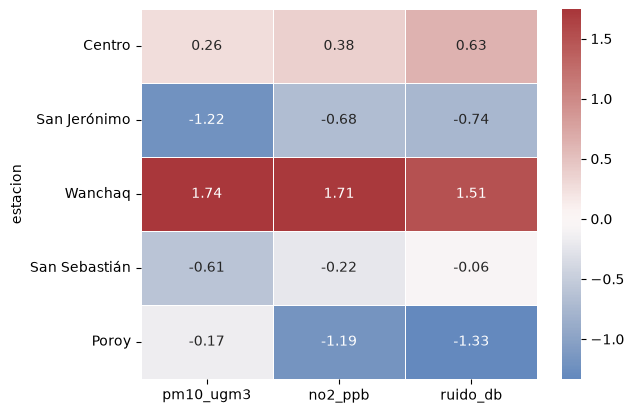

In [8]:
import seaborn as sns
sns.heatmap(df_z, cmap='vlag', center=0, annot=True, fmt='.2f', linewidths=0.5)


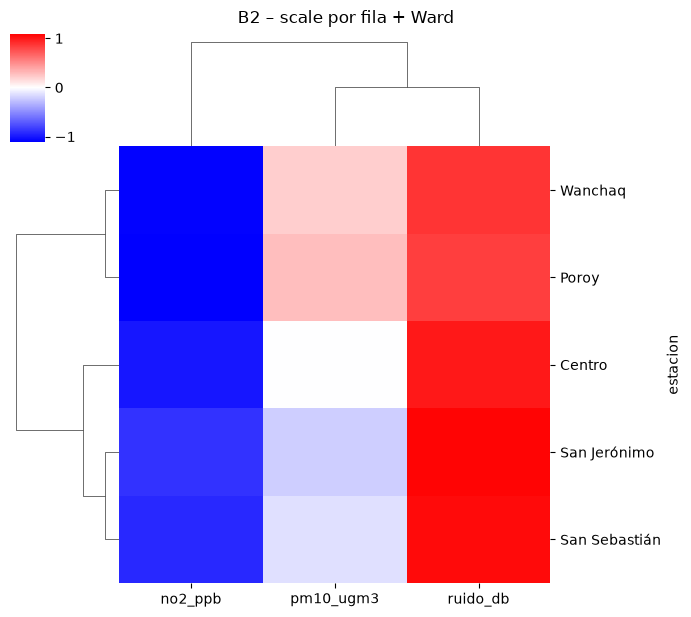

In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

matriz_data = df_clean.copy()

# Equivalente a scale = "row" (Z por fila, desviación muestral ddof=1)
row_scaled = (matriz_data.sub(matriz_data.mean(axis=1), axis=0)
                         .div(matriz_data.std(axis=1, ddof=1), axis=0))

cmap_br = LinearSegmentedColormap.from_list('blue_white_red', ['blue', 'white', 'red'])

g = sns.clustermap(row_scaled, method='ward', metric='euclidean',
                   cmap=cmap_br, center=0, figsize=(7, 6))
g.figure.suptitle('B2 – scale por fila + Ward', y=1.02)
plt.show()

In [10]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, MinMaxScaler

df = pd.read_excel('datos_ambiental_evaluacion_tema9.xlsx', index_col='estacion')
num_cols = ['pm10_ugm3', 'no2_ppb', 'ruido_db']

# Imputación con la mediana
df_clean = df[num_cols].fillna(df[num_cols].median())

# Z-score por columna (sklearn usa desviación poblacional, ddof=0)
df_z = pd.DataFrame(StandardScaler().fit_transform(df_clean),
                    index=df_clean.index, columns=num_cols)

# Min-Max [0, 1]
df_mm = pd.DataFrame(MinMaxScaler().fit_transform(df_clean),
                     index=df_clean.index, columns=num_cols)

print(df_z.round(2))

               pm10_ugm3  no2_ppb  ruido_db
estacion                                   
Centro              0.26     0.38      0.63
San Jerónimo       -1.22    -0.68     -0.74
Wanchaq             1.74     1.71      1.51
San Sebastián      -0.61    -0.22     -0.06
Poroy              -0.17    -1.19     -1.33


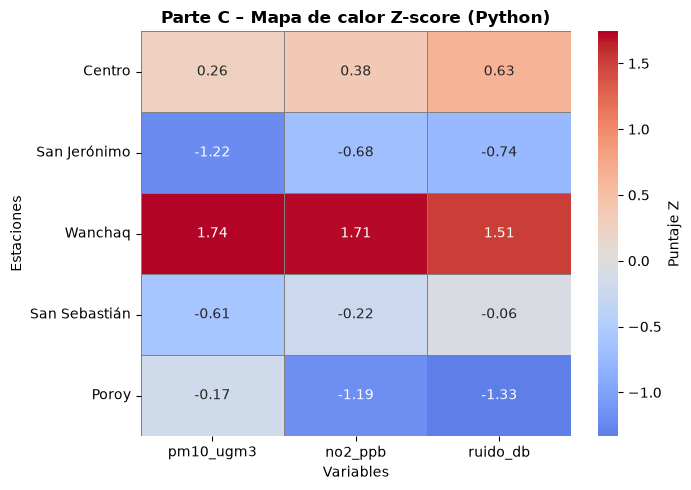

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))
ax = sns.heatmap(df_z, cmap='coolwarm', center=0, annot=True, fmt='.2f',
                 linewidths=0.5, linecolor='gray',
                 cbar_kws={'label': 'Puntaje Z'})
ax.set_title('Parte C – Mapa de calor Z-score (Python)', fontweight='bold')
ax.set_xlabel('Variables')
ax.set_ylabel('Estaciones')
plt.tight_layout()
plt.savefig('parteC_heatmap_python.png', dpi=150)
plt.show()

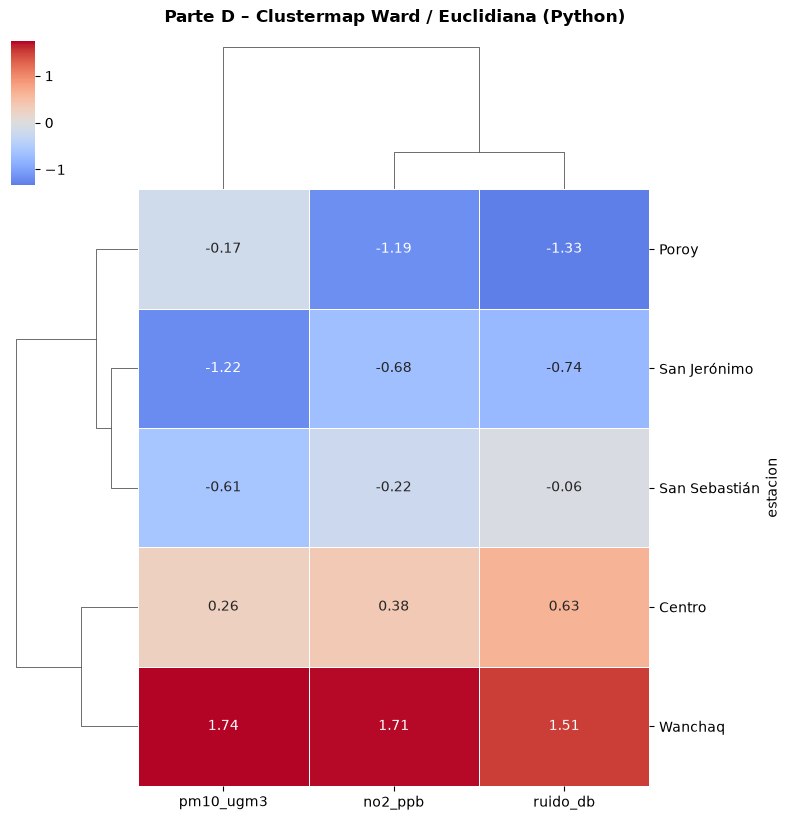

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

g = sns.clustermap(df_z,
                   metric='euclidean',
                   method='ward',
                   cmap='coolwarm',
                   center=0,
                   annot=True, fmt='.2f',
                   linewidths=0.5,
                   figsize=(8, 8),
                   dendrogram_ratio=(0.2, 0.2),
                   cbar_pos=(0.02, 0.8, 0.03, 0.18))

g.figure.suptitle('Parte D – Clustermap Ward / Euclidiana (Python)',
                  fontweight='bold', y=1.02)
g.savefig('parteD_clustermap_python.png', dpi=300, bbox_inches='tight')
plt.show()